In [3]:
# !pip install scikit-optimize
# !pip install pyDOE
# !pip install smt

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.3/100.3 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pyDOE: filename=pyDOE-0.3.8-py3-none-any.whl size=18168 sha256=392e50d3dbb2ceab34697b10c9cf818e304bca9c0b4be94e4d0f36232340bd69
  Stored in directory: /root/.cache/pip/wheels/ce/b6/d7/c6b64746dba6433c593e471e0ac3acf4f36040456d1d160d17
Successfully built pyDOE
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.3/835.3 kB 11.2 MB/s eta 0:00:00


In [4]:
# Support for math
import numpy as np
import math

# Plotting tools
from matplotlib import pyplot as plt
import matplotlib

import warnings
warnings.filterwarnings('ignore')

# GPy: Gaussian processes library
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

# File tools
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

#Sampling
from pyDOE import lhs

Mounted at /content/drive


#Generate points

In [5]:
from pyDOE import lhs
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint):
    # Step 1: Generate Latin Hypercube Samples
    np.random.seed(2)
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # Step 2: Transform samples to satisfy the sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

sampled_colors = latin_hypercube_sum_constraint(12, 3, 300)//1
sampled_colors.transpose()

array([[ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
         15.],
       [ 39.,  76.,  78., 122., 128., 124., 153.,  37., 125., 100.,  39.,
         69.],
       [177.,  57., 116., 150.,  62.,  91., 114.,  47.,  59.,  59.,  46.,
        214.]])

#import data

In [6]:
# Path
xls = pd.read_excel("/content/drive/MyDrive/SunLab /data/02_23_Random_Color_Increment.xlsx",sheet_name=['End point','RGB'])

df = xls.get('End point')
df_RGB = xls.get('RGB')

df.head()

,Well\nRow,Well\nCol,Content,Concentration,Raw Data (Abs Spectrum),Raw Data (Abs Spectrum).1,Raw Data (Abs Spectrum).2,Raw Data (Abs Spectrum).3,Raw Data (Abs Spectrum).4,Raw Data (Abs Spectrum).5,...,Raw Data (Abs Spectrum).141,Raw Data (Abs Spectrum).142,Raw Data (Abs Spectrum).143,Raw Data (Abs Spectrum).144,Raw Data (Abs Spectrum).145,Raw Data (Abs Spectrum).146,Raw Data (Abs Spectrum).147,Raw Data (Abs Spectrum).148,Raw Data (Abs Spectrum).149,Raw Data (Abs Spectrum).150
0,NaN,NaN,Wavelength [nm],NaN,400.000,402.000,404.000,406.000,408.000,410.000,...,682.000,684.000,686.000,688.000,690.000,692.000,694.000,696.000,698.000,700.000
1,D,1.0,Sample X37,74626.252,1.363,1.391,1.409,1.438,1.459,1.474,...,0.043,0.042,0.040,0.038,0.035,0.034,0.033,0.031,0.030,0.030
2,D,2.0,Sample X38,25529.573,0.627,0.648,0.663,0.677,0.689,0.694,...,0.066,0.061,0.056,0.051,0.047,0.043,0.041,0.037,0.036,0.035
3,D,3.0,Sample X39,42472.278,0.997,1.023,1.044,1.065,1.080,1.093,...,0.067,0.061,0.057,0.053,0.050,0.047,0.044,0.041,0.040,0.038
4,D,4.0,Sample X40,32500.649,1.461,1.497,1.528,1.560,1.574,1.584,...,0.277,0.267,0.260,0.253,0.247,0.243,0.239,0.236,0.234,0.231


Inputs

In [7]:
vol_red  = sampled_colors[:,0]
vol_blue = sampled_colors[:,1]
vol_yelo = sampled_colors[:,2]
vol_red

array([ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
        15.])

Outputs

In [8]:
colors_R = np.array(df_RGB.loc[:,'R/255'])
colors_G = np.array(df_RGB.loc[:,'G/255'])
colors_B = np.array(df_RGB.loc[:,'B/255'])

colors_RGB = list(zip(colors_R,colors_G,colors_B))

colors_R

array([0.3254902 , 0.1254902 , 0.1372549 , 0.        , 0.00392157,
       0.        , 0.00784314, 0.24705882, 0.01176471, 0.05882353,
       0.21176471, 0.        ])

#Gaussian Process

In [9]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C
from sklearn.model_selection import train_test_split

# Combine RGB channels into a single target variable
y = np.column_stack((colors_R, colors_G, colors_B))
x = sampled_colors
#Split
X_train, X_test,y_train,y_test  = train_test_split(x, y, test_size=0.3,random_state=42)


# Define the kernel for GPR
kernel = C(1.0, (1e-3, 1e3)) * RBF(1.0, (1e-2, 1e2))

# Create GPR model
gpr_model = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, random_state=42)

# Fit the model to the training data
gpr_model.fit(X_train, y_train)

# Generate predictions for the test data
y_pred, sigma = gpr_model.predict(X_test, return_std=True)

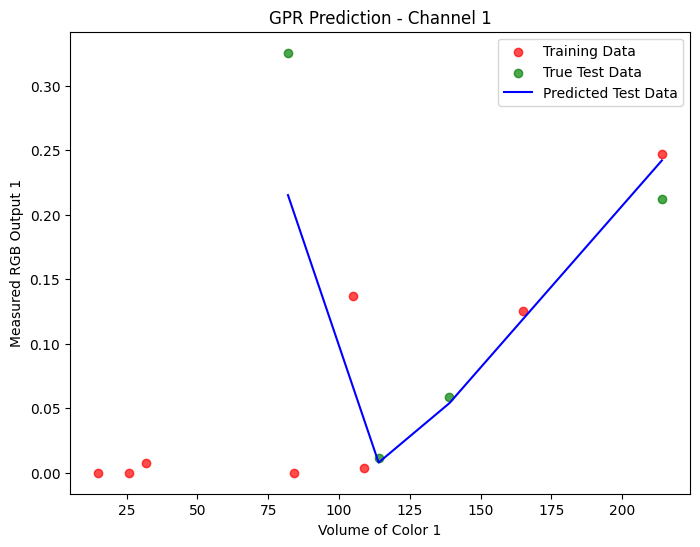

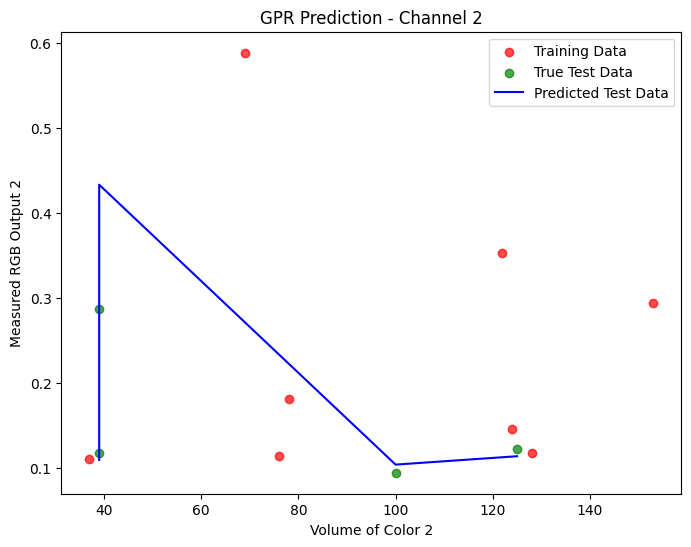

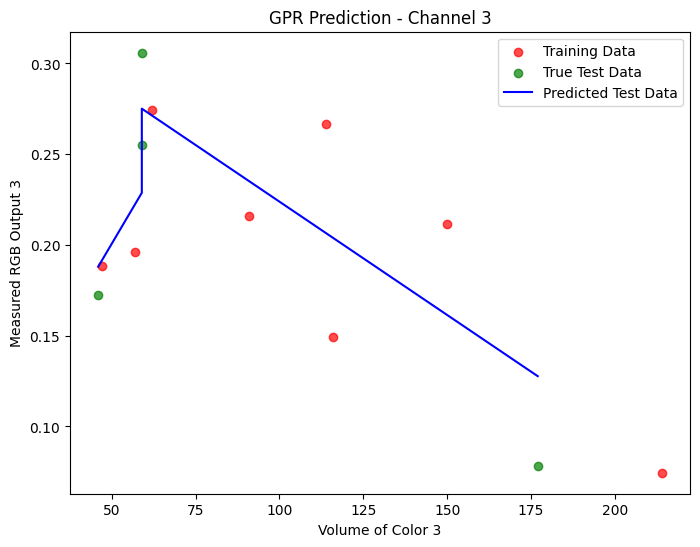

In [15]:
# Plot the results for each RGB channel in separate 2D plots
for i in range(3):
    pair = np.array([X_test[:, i],y_pred[:, i],sigma[:, i]]).transpose()
    pair = pair[pair[:,0].argsort()]

    plt.figure(figsize=(8, 6))

    # Plot training data
    plt.scatter(X_train[:, i], y_train[:, i], c='r', label='Training Data', alpha=0.7)

    # Plot true test data
    plt.scatter(X_test[:, i], y_test[:, i], c='g', label='True Test Data', alpha=0.7)

    # Plot predicted test data
    #plt.plot(X_test[:, i], y_pred[:, i], 'b-', label='Predicted Test Data')
    plt.plot(pair[:,0], pair[:,1], 'b-', label='Predicted Test Data')

    # Fill uncertainty region
    #plt.fill_between(X_test[:, i], y_pred[:, i].shape - 1.96 * sigma[:, i] ,y_pred[:, i] + 1.96 * sigma[:, i], alpha=0.2)
    #plt.fill_between(pair[:,0], pair[:,1].shape - 1.96 * pair[:,2] ,pair[:,1] + 1.96 * pair[:,2] , alpha=0.2)

    plt.title(f'GPR Prediction - Channel {i+1}')
    plt.xlabel(f'Volume of Color {i+1}')
    plt.ylabel(f'Measured RGB Output {i+1}')
    plt.legend()
    plt.show()

Optimal Parameters: [111.23366107712897, 197.46906785662864, 0.0]
Optimal Volume: [[111.23366108 197.46906786   0.        ]]
Predicted RGB Value: [0.088923   0.18359261 0.41876643]


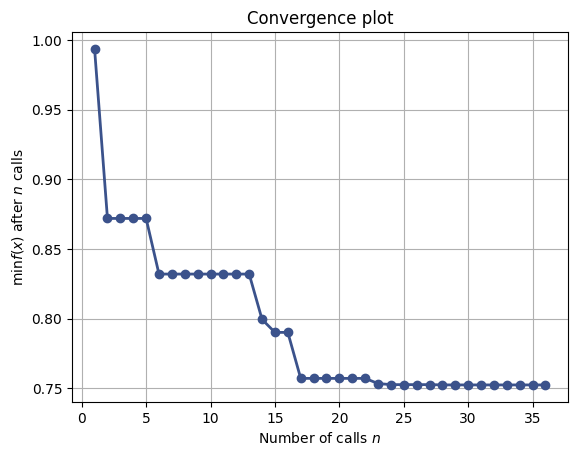

In [11]:
from skopt import gp_minimize
from scipy.spatial.distance import euclidean

# # Define the objective function (negative of the predicted RGB value)
# def objective(params):
#     params = np.array(params).reshape(1, -1)
#     return -gpr_model.predict(params)[0][0]  # Optimize for the first RGB channel

# Define the target RGB color
# target_rgb = np.array([160, 32, 240])
# # Modify the objective function to minimize the mean squared error between the predicted and target RGB values
# def objective(params):
#     params = np.array(params).reshape(1, -1)
#     predicted_rgb = gpr_model.predict(params)[0]
#     mse = mean_squared_error(target_rgb, predicted_rgb)
#     return mse

# Reference RGB value (the desired or ideal RGB you want to achieve)
reference_rgb = np.array([160/255, 32/255, 240/255])

# Modify the objective function to minimize the L2 distance between the predicted and reference RGB values
def objective(params):
    params = np.array(params).reshape(1, -1)
    predicted_rgb = gpr_model.predict(params)[0]
    distance = euclidean(reference_rgb, predicted_rgb)
    return distance



# Define the parameter search space
param_space = [(0.0, 300.0),  # volume_0
               (0.0, 300.0),  # volume_1
               (0.0, 300.0)]  # volume_2

# Perform Bayesian Optimization
result = gp_minimize(objective, param_space, n_calls=36, random_state=42)

# Get the optimal parameters
optimal_params = result.x
optimal_volume = np.array(optimal_params).reshape(1, -1)

# Predict the optimal RGB value
optimal_rgb = gpr_model.predict(optimal_volume)[0]

# Print the optimal parameters and predicted RGB value
print("Optimal Parameters:", optimal_params)
print("Optimal Volume:", optimal_volume)
print("Predicted RGB Value:", optimal_rgb)

from skopt.plots import plot_convergence
plot_convergence(result);


In [12]:
def sum_constraint(n_samples,sum_constraint):
    for i in range(len(n_samples)):
        if sum(n_samples[i]) == 0:
          n_samples[i, :] = sum_constraint/len(n_samples[i])
        current_sum = np.sum(n_samples[i, :])
        n_samples[i, :] *= sum_constraint / current_sum
    return n_samples

In [13]:
x_iterations = np.array(result.x_iters)## This produces NAN
BO_x = sum_constraint(x_iterations,300)//1
rgb_predict = gpr_model.predict(x_iterations)

#for i in range(len(rgb_predict)):
#plt.plot(BO_x[:,0],'o',color =list(rgb_predict[i]))

#plt.plot(X_train[:,i],y_train[:,i],'o')

# plt.plot()
# plt.plot(BO_x[:,1],rgb_predict[:,1],'o')
# plt.plot(BO_x[:,2],rgb_predict[:,2],'o')



In [14]:
BO_x = sum_constraint(np.array(result.x_iters),300)//1
BO_x_M = BO_x[:,0]
BO_x_B = BO_x[:,1]
BO_x_Y = BO_x[:,2]
BO_x_M,BO_x_B,BO_x_Y


(array([135., 156., 147., 136., 145., 149.,   7.,  11.,  24., 127., 162.,
         41., 115., 146., 140., 202., 112.,   0.,  95., 100.,  94., 300.,
        111., 105.,   0.,   0., 300., 109., 108., 108., 107., 110., 107.,
        107., 109., 107.]),
 array([ 31., 117., 106.,  11.,   0., 148., 166., 233., 169.,  60., 137.,
         67., 184., 153., 159.,   0., 187., 300., 178., 100., 205.,   0.,
        188., 194., 150.,   0.,   0., 190., 191., 191., 192., 189., 192.,
        192., 190., 192.]),
 array([132.,  26.,  45., 151., 154.,   1., 126.,  55., 105., 111.,   0.,
        190.,   0.,   0.,   0.,  97.,   0.,   0.,  26., 100.,   0.,   0.,
          0.,   0., 150., 300.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.]))